In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
df=pd.read_csv('/content/gender_classification_v7.csv')

In [3]:
df.head()

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,Male
1,0,14.0,5.4,0,0,1,0,Female
2,0,11.8,6.3,1,1,1,1,Male
3,0,14.4,6.1,0,1,1,1,Male
4,1,13.5,5.9,0,0,0,0,Female


In [4]:
df.tail()

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
4996,1,13.6,5.1,0,0,0,0,Female
4997,1,11.9,5.4,0,0,0,0,Female
4998,1,12.9,5.7,0,0,0,0,Female
4999,1,13.2,6.2,0,0,0,0,Female
5000,1,15.4,5.4,1,1,1,1,Male


In [5]:
df.shape

(5001, 8)

In [6]:
df.isnull().sum()

,0
long_hair,0
forehead_width_cm,0
forehead_height_cm,0
nose_wide,0
nose_long,0
lips_thin,0
distance_nose_to_lip_long,0
gender,0


In [7]:
df.duplicated().sum()

np.int64(1768)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(3233, 8)

In [10]:
cat_columns=df.select_dtypes(include='object').columns
cat_columns

Index(['gender'], dtype='object')

In [11]:
num_columns=df.select_dtypes(exclude='object').columns
num_columns

Index(['long_hair', 'forehead_width_cm', 'forehead_height_cm', 'nose_wide',
       'nose_long', 'lips_thin', 'distance_nose_to_lip_long'],
      dtype='object')

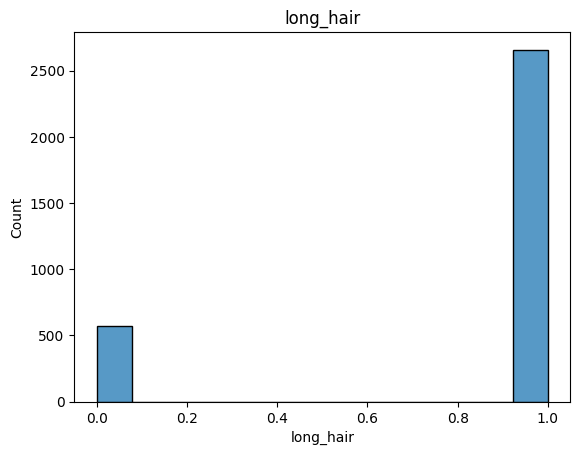

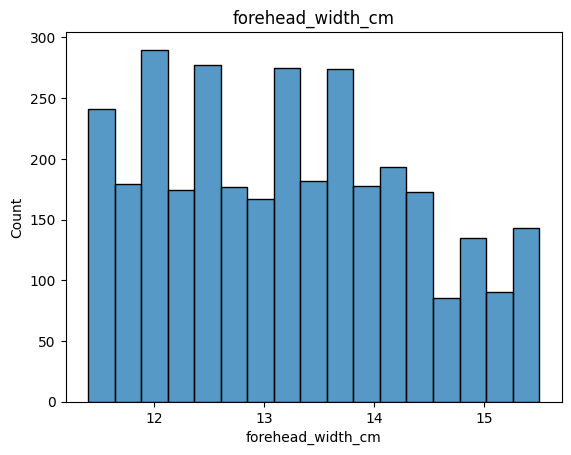

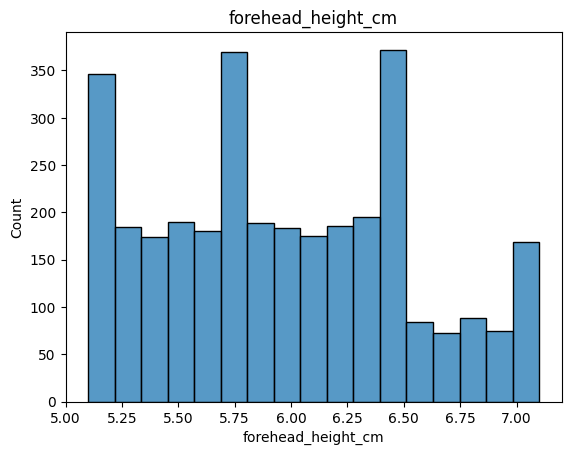

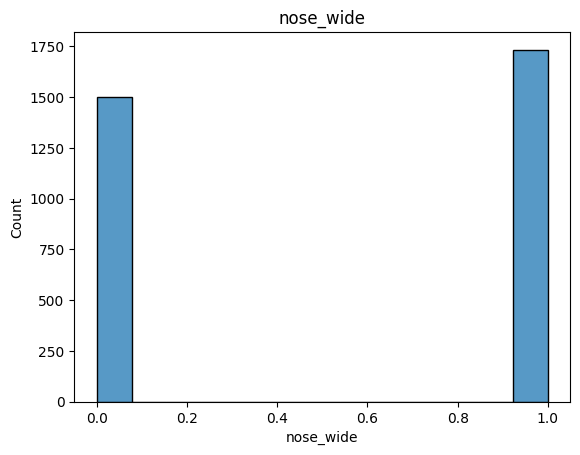

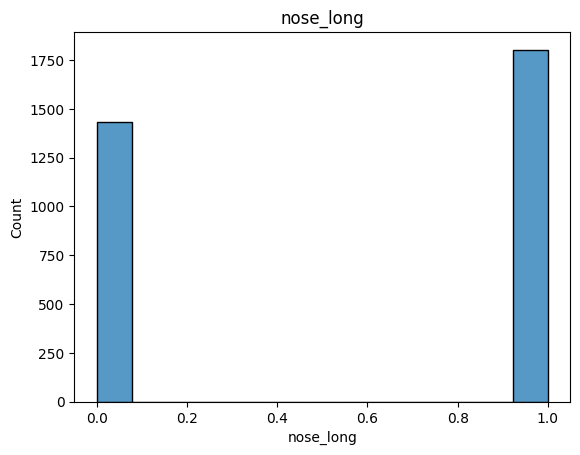

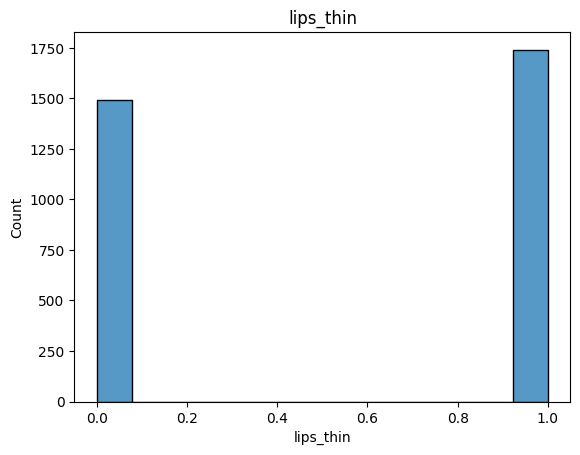

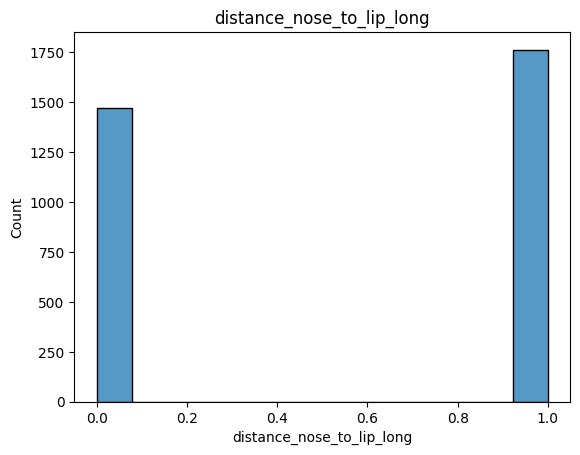

In [12]:
for i in num_columns:
  sns.histplot(df[i])
  plt.title(i)
  plt.show()

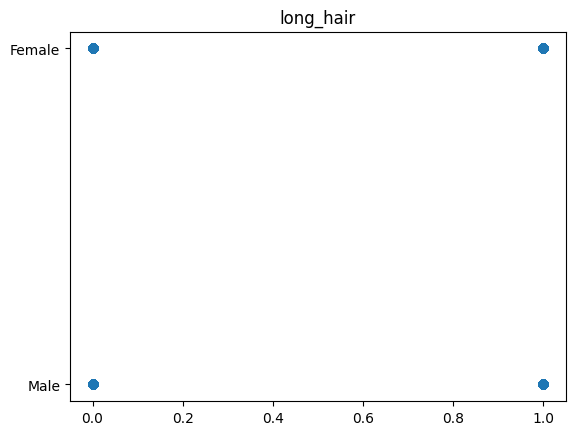

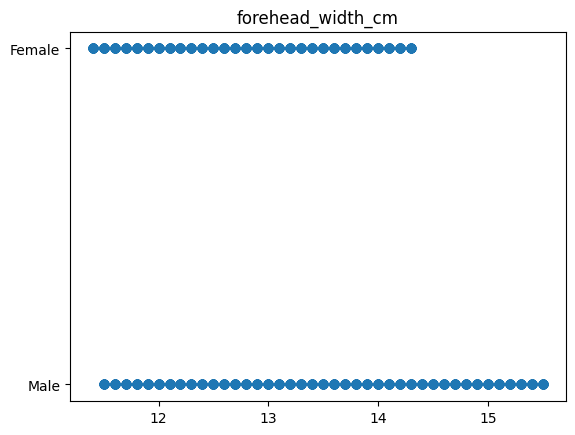

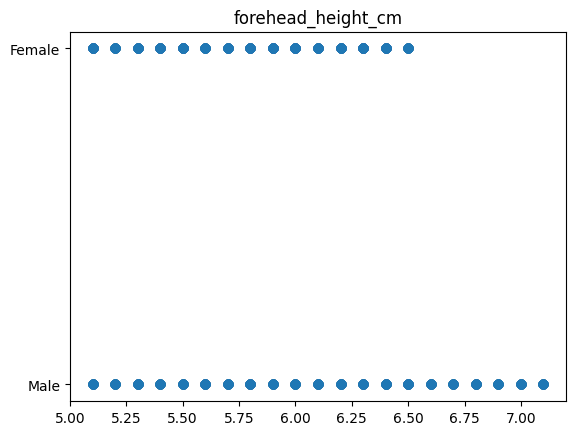

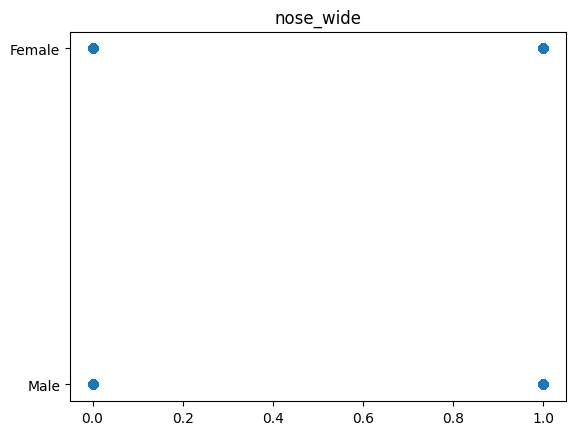

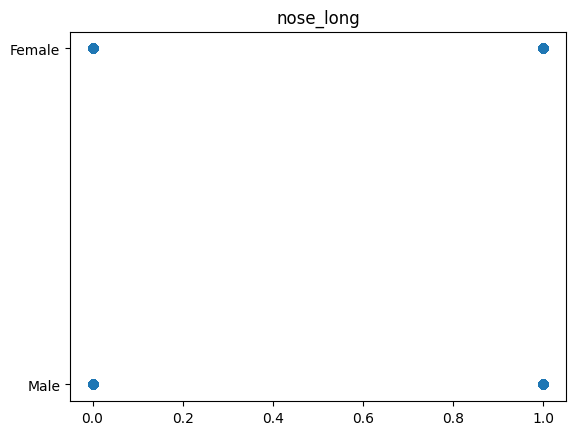

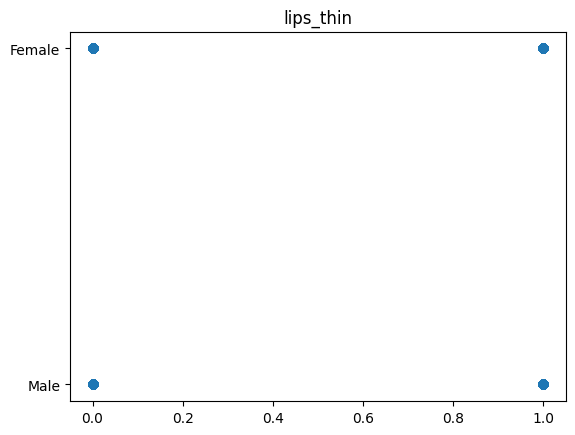

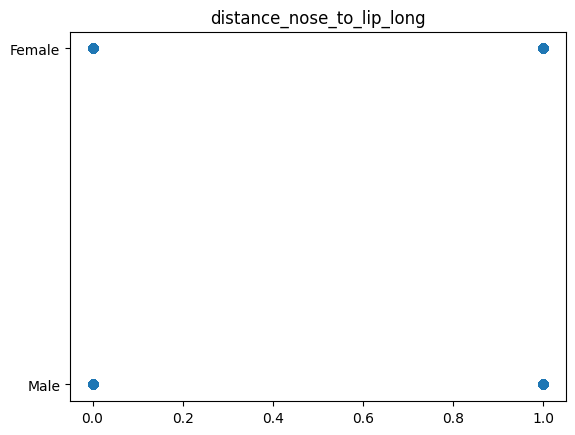

In [15]:
for i in num_columns:
  plt.scatter(df[i],df['gender'])
  plt.title(i)
  plt.show()

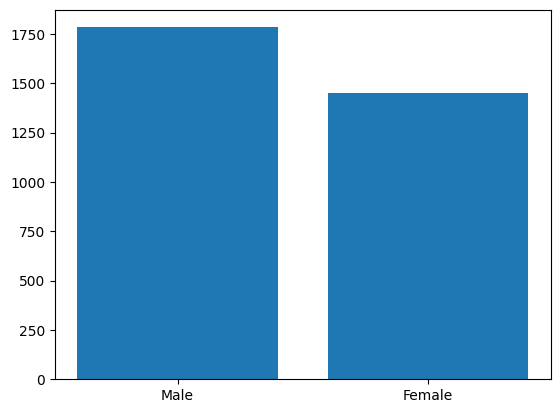

In [16]:
plt.bar(df["gender"].value_counts().index,df["gender"].value_counts())
plt.show()

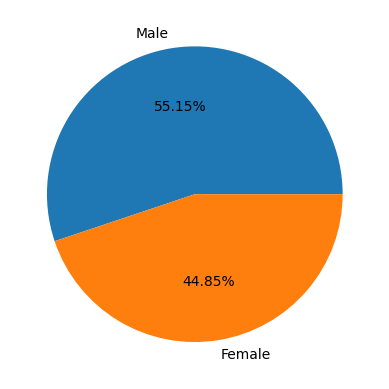

In [17]:
plt.pie(df["gender"].value_counts(),labels=df["gender"].value_counts().index,autopct="%1.2f%%")
plt.show()

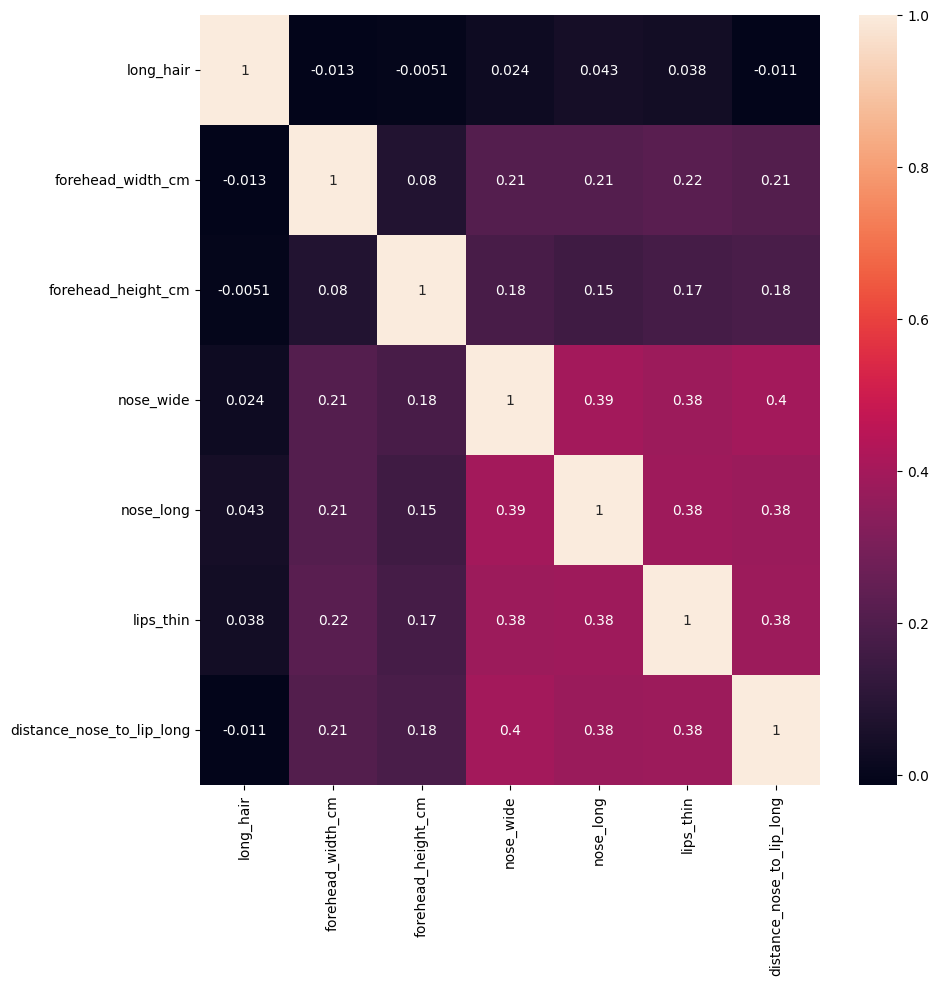

In [19]:
plt.figure(figsize=(10,10))
sns.heatmap(df[num_columns].corr(),annot=True)
plt.show()

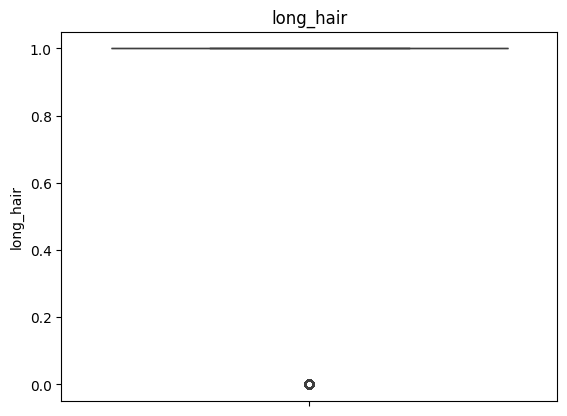

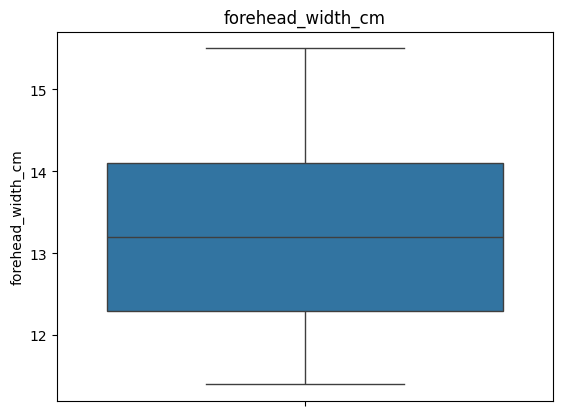

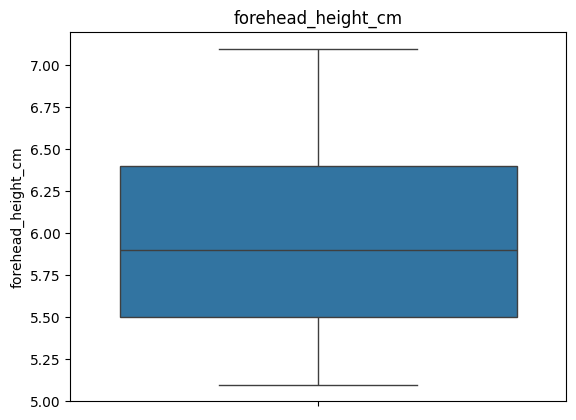

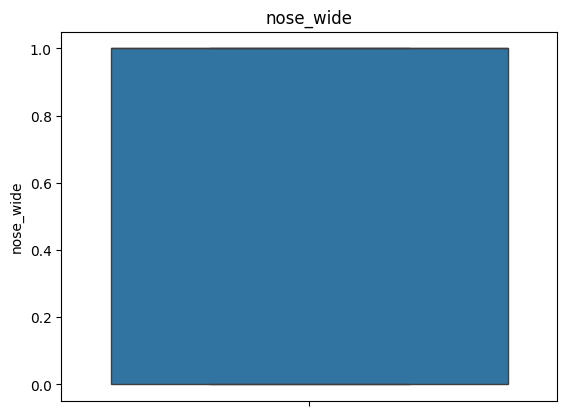

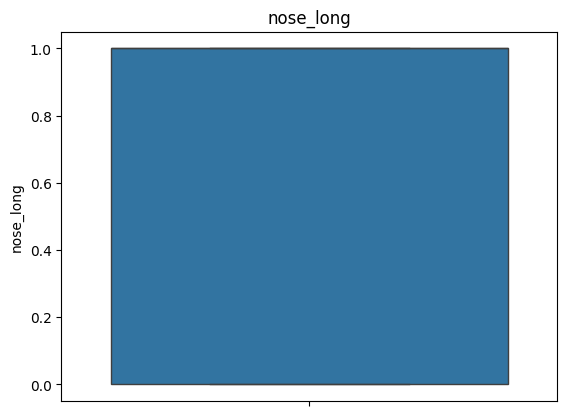

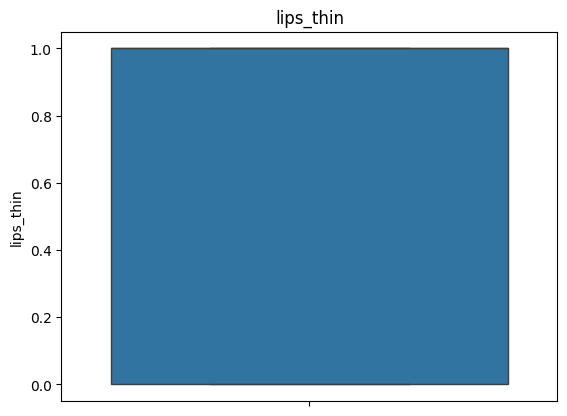

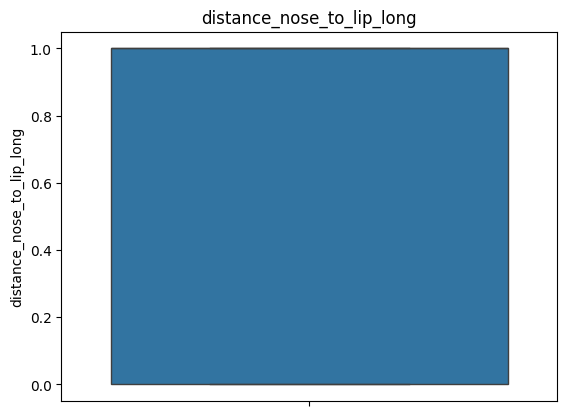

In [20]:
for i in num_columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

In [21]:
df["gender"].value_counts()

,count
gender,
Male,1783
Female,1450


In [22]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in cat_columns:
    df[col] = le.fit_transform(df[col])

In [23]:
from sklearn.model_selection import train_test_split
X = df.drop('gender', axis=1)
y = df['gender']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
log_model=LogisticRegression()
y_train = y_train.round().astype(int)
y_test = y_test.round().astype(int)
log_model.fit(X_train,y_train)

LogisticRegression()

In [27]:
param_grid = [
    {'penalty' : ['l1', 'l2', 'elasticnet', 'none'],
    'C' : np.logspace(-4, 4, 20),
    'solver' : ['lbfgs','newton-cg','liblinear','sag','saga'],
    'max_iter' : [100, 1000,2500, 5000]
    }
]

In [28]:
from sklearn.model_selection import GridSearchCV
clf=GridSearchCV(log_model,param_grid=param_grid,cv=5,verbose=True,n_jobs=-1)
best_clf=clf.fit(X_train,y_train)

Fitting 5 folds for each of 1600 candidates, totalling 8000 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
5200 fits failed out of a total of 8000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
400 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_s

In [29]:
best_clf.best_estimator_

LogisticRegression(C=np.float64(1.623776739188721))

In [30]:
y_original = df['gender'].round().astype(int)
print(f"accuracy is : {best_clf.score(X,y_original):.3f}")

accuracy is : 0.952


[[296  12]
 [ 14 325]]


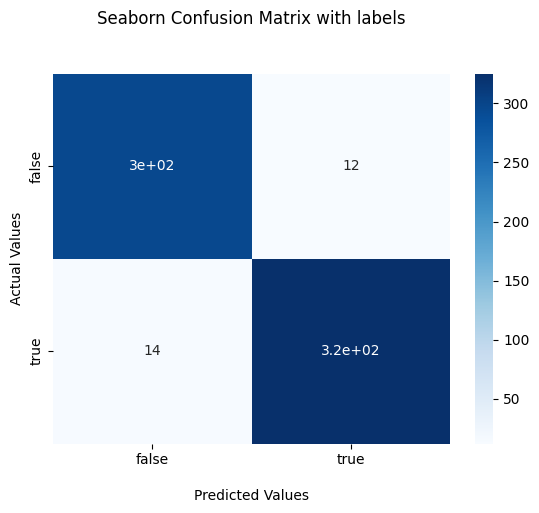

In [31]:
from sklearn.metrics import confusion_matrix
y_pred=log_model.predict(X_test)
cf_matrix=confusion_matrix(y_test,y_pred)
print(cf_matrix)
ax=sns.heatmap(cf_matrix,annot=True,cmap="Blues")
ax.set_title('Seaborn Confusion Matrix with labels\n\n')
ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values')
ax.xaxis.set_ticklabels(["false","true"])
ax.yaxis.set_ticklabels(["false","true"])
plt.show()

In [32]:
from sklearn.metrics import classification_report
from sklearn import metrics
y_pred=log_model.predict(X_test)
print(classification_report(y_test,y_pred))
accracy=metrics.accuracy_score(y_test,y_pred)
f1_score=metrics.f1_score(y_test,y_pred)
precision=metrics.precision_score(y_test,y_pred)
recall=metrics.recall_score(y_test,y_pred)
print (f'logictic regression model Accuracy: {100*accracy:.3} %')
print (f'logictic regression model f1_score: {100*f1_score:.3} %')
print (f'logictic regression model precision: {100*precision:.3} %')
print (f'logictic regression model recall: {100*recall:.3}  %')

              precision    recall  f1-score   support

           0       0.95      0.96      0.96       308
           1       0.96      0.96      0.96       339

    accuracy                           0.96       647
   macro avg       0.96      0.96      0.96       647
weighted avg       0.96      0.96      0.96       647

logictic regression model Accuracy: 96.0 %
logictic regression model f1_score: 96.2 %
logictic regression model precision: 96.4 %
logictic regression model recall: 95.9  %


In [33]:
y_pred1=log_model.predict_proba(X_test)[:,1]
print(y_pred1)

[4.50754446e-01 4.04027730e-01 3.53852270e-02 9.99424787e-01
 9.99182991e-01 6.62379522e-01 1.04930585e-02 9.99713271e-01
 9.44569749e-03 9.47267409e-04 5.64833659e-04 9.89888463e-01
 9.87948457e-01 9.98763366e-01 6.66156245e-02 9.99503470e-01
 1.49025642e-03 9.70871818e-01 9.90992767e-01 9.80561858e-01
 9.99571258e-01 9.79536079e-01 9.70204937e-01 1.48127589e-02
 9.93653737e-01 5.58183556e-02 9.99217659e-01 1.56063009e-02
 2.37050799e-04 1.23253615e-02 9.91256443e-01 2.81337641e-02
 9.99770880e-01 9.85566784e-01 9.99433879e-01 9.38714402e-04
 9.96671020e-01 2.49770325e-03 9.99738511e-01 1.71995892e-02
 9.84119435e-01 9.99730639e-01 9.99491379e-01 1.64383353e-02
 3.50766462e-02 2.26286679e-02 3.45274091e-04 9.99564372e-01
 9.99652328e-01 9.49928126e-01 9.99603216e-01 5.50352034e-01
 9.11298732e-04 2.35087795e-01 9.59832866e-01 1.35077242e-02
 9.98881249e-01 9.96410578e-01 2.07744380e-03 9.98543206e-01
 2.47284431e-03 9.85843519e-01 9.97546979e-01 1.84989002e-03
 3.90487684e-04 9.996946

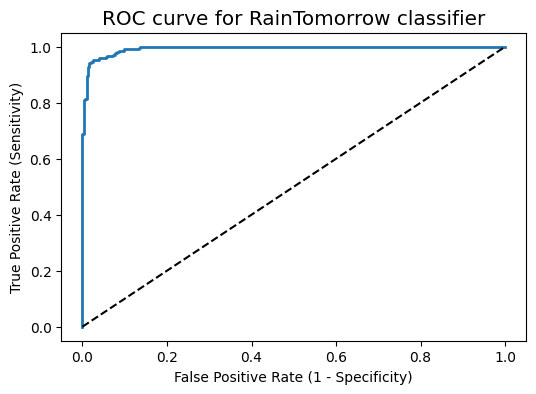

In [34]:
y_pred1=log_model.predict_proba(X_test)[:,1]
from sklearn.metrics import roc_curve
fpr , tpr , thresholds = roc_curve(y_test,y_pred1)
plt.figure(figsize=(6,4))
plt.plot(fpr,tpr,linewidth=2)
plt.plot([0,1],[0,1],"k--")
plt.rcParams['font.size'] = 12
plt.title('ROC curve for RainTomorrow classifier')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.show()

In [35]:
from sklearn.metrics import roc_auc_score
roc_auc=roc_auc_score(y_test,y_pred1)
print("ROC AUC : {:.3f}".format(roc_auc))

ROC AUC : 0.994


In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [37]:
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)

In [38]:
y_pred = dt_model.predict(X_test)

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9536321483771252

 Confusion Matrix:
 [[305   3]
 [ 27 312]]

 Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.99      0.95       308
           1       0.99      0.92      0.95       339

    accuracy                           0.95       647
   macro avg       0.95      0.96      0.95       647
weighted avg       0.96      0.95      0.95       647



In [40]:
DT_Model = DecisionTreeClassifier()
params = {
    'max_depth': [3,5,7,12],
    'min_samples_leaf': list(range(2,10)),
    'min_samples_split': list(range(2,10)),
    'criterion': ["gini", "entropy"]
}
grid_search = GridSearchCV(estimator=DT_Model,
                           param_grid=params,
                           cv=5)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 12],
                         'min_samples_leaf': [2, 3, 4, 5, 6, 7, 8, 9],
                         'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9]})

In [41]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 8}
0.9532071723561085


In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\n Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9536321483771252

 Confusion Matrix:
 [[305   3]
 [ 27 312]]

 Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.99      0.95       308
           1       0.99      0.92      0.95       339

    accuracy                           0.95       647
   macro avg       0.95      0.96      0.95       647
weighted avg       0.96      0.95      0.95       647



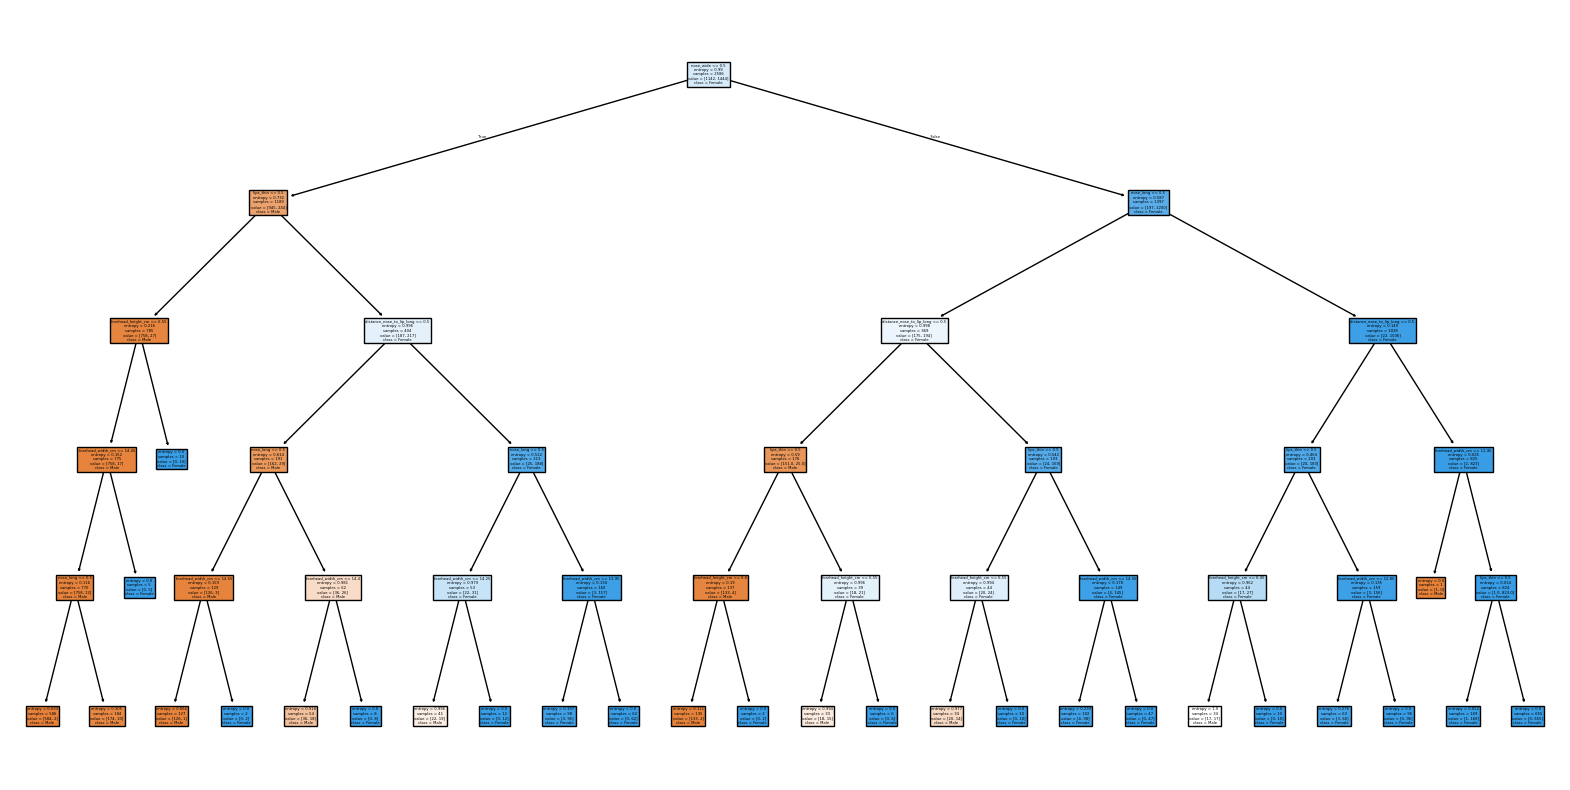

In [44]:
from sklearn import tree
plt.figure(figsize=(20,10))
tree.plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Male", "Female"],
    filled=True,
)
plt.show()

In [45]:
y_pred1=log_model.predict_proba(X_test)[:,1]
print(y_pred1)

[4.50754446e-01 4.04027730e-01 3.53852270e-02 9.99424787e-01
 9.99182991e-01 6.62379522e-01 1.04930585e-02 9.99713271e-01
 9.44569749e-03 9.47267409e-04 5.64833659e-04 9.89888463e-01
 9.87948457e-01 9.98763366e-01 6.66156245e-02 9.99503470e-01
 1.49025642e-03 9.70871818e-01 9.90992767e-01 9.80561858e-01
 9.99571258e-01 9.79536079e-01 9.70204937e-01 1.48127589e-02
 9.93653737e-01 5.58183556e-02 9.99217659e-01 1.56063009e-02
 2.37050799e-04 1.23253615e-02 9.91256443e-01 2.81337641e-02
 9.99770880e-01 9.85566784e-01 9.99433879e-01 9.38714402e-04
 9.96671020e-01 2.49770325e-03 9.99738511e-01 1.71995892e-02
 9.84119435e-01 9.99730639e-01 9.99491379e-01 1.64383353e-02
 3.50766462e-02 2.26286679e-02 3.45274091e-04 9.99564372e-01
 9.99652328e-01 9.49928126e-01 9.99603216e-01 5.50352034e-01
 9.11298732e-04 2.35087795e-01 9.59832866e-01 1.35077242e-02
 9.98881249e-01 9.96410578e-01 2.07744380e-03 9.98543206e-01
 2.47284431e-03 9.85843519e-01 9.97546979e-01 1.84989002e-03
 3.90487684e-04 9.996946

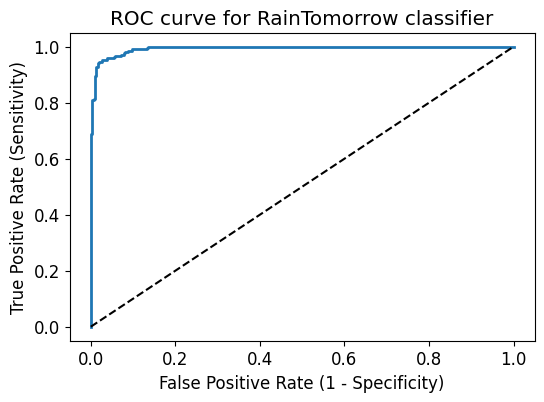

In [46]:
y_pred1=log_model.predict_proba(X_test)[:,1]
from sklearn.metrics import roc_curve
fpr , tpr , thresholds = roc_curve(y_test,y_pred1)
plt.figure(figsize=(6,4))
plt.plot(fpr,tpr,linewidth=2)
plt.plot([0,1],[0,1],"k--")
plt.rcParams['font.size'] = 12
plt.title('ROC curve for RainTomorrow classifier')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.show()

In [47]:
from sklearn.metrics import roc_auc_score
roc_auc=roc_auc_score(y_test,y_pred1)
print("ROC AUC : {:.3f}".format(roc_auc))

ROC AUC : 0.994
